# Step 8 — Construction sensitivity and realized policy surprises
Run **Runtime → Run all**, then save to GitHub as **07_construction_and_policy_surprise.ipynb**. Standalone: setup visibly rebuilds the validated candidate dataset and imports the tested analysis tools. No earlier Colab runtime is required.

We keep the primary Treasury specification unchanged. This notebook checks whether alternative uncertainty definitions and a different treatment of the stored adjusted CDF change the association. It then calculates the supporting realized target-rate surprise using consistent midpoint units.

**Construction limit:** differencing the published adjusted CDF can avoid the final probability reallocations, but retains the earlier monotonicity corrections, forward-filled prices, bin support and 1/99 endpoint convention. It cannot establish robustness to the entire construction pipeline. Entropy and 1−max probability also use the same processed distribution.

**Target convention:** the authors' +0.125 percentage-point adjustment represents a bin midpoint. We compare that midpoint-based expectation with the actual target-range midpoint. In this 25-bp-wide-range sample, both actual and expected upper-bound rates can be obtained by adding 12.5 bps. The shift cancels in the surprise. These are approximations under the authors' distribution construction, not an exact raw discrete-decision reconstruction.

**Effective dates:** FRED DFEDTARU and DFEDTARL describe rates effective that day. Scheduled decisions in this sample take effect the next day; we compare day−1 to day+1 and verify day-of levels and day+2 stability. Unexpected timing or missing data stops the calculation.

**Interpretation:** greater dispersion can mechanically imply greater expected absolute deviation. Dispersion-surprise association is not by itself incremental predictive skill. Realized surprise is post-announcement and is never entered into the ex-ante Treasury model. All supporting models and alternate definitions are exploratory; their p-values are not confirmatory or family-wide adjusted.

Sources: [construction code](https://github.com/jdkatz21/Prediction_Markets_Public/blob/main/code/convert_trades_to_pdfs/convert_trade_level_data_cdfs.R), [FRED upper bound](https://fred.stlouisfed.org/series/DFEDTARU), [FRED lower bound](https://fred.stlouisfed.org/series/DFEDTARL), [official target changes](https://www.federalreserve.gov/monetarypolicy/openmarket.htm), [September 2024 statement](https://www.federalreserve.gov/newsevents/pressreleases/monetary20240918a.htm), [implementation note](https://www.federalreserve.gov/newsevents/pressreleases/monetary20240918a1.htm).

**Rerun fix:** policy, diagnostics and plotting cells rebuild their input table rather than merging repeatedly into a mutable previous result. If prerequisites have not run, the plotting cell names the missing steps.

**FRED timeout fix:** section 2 uses an embedded, checksum-verified subset of official FRED observations retrieved on October 19, 2026. It covers the four effective-date checks for all 37 historical meetings. It makes no live FRED request and fills no missing values; extending the sample requires updating and verifying that snapshot.

## Verified initial run — October 19, 2026
All 12 code cells executed successfully. Actual target-rate calculations reconcile for all 37 events, and the September 2024 50-bp cut matches the official statement and implementation note.

The stored-CDF alternative changes uncertainty for **9 of 37 meetings**. The other 28 reproduce the reference sigma, providing an identity check. Some retained tail masses make the alternative much larger—for example, December 2022 rises from approximately **8.48 to 144.16 bps**. The adjusted alternative-sigma interval includes zero; entropy and 1−max probability remain positive in exploratory comparisons. This documents dependence on construction; the tail-sensitive alternative is not automatically a better measure, and these checks do not validate raw quote freshness.

Kalshi dispersion and realized target surprise are positively associated, but the distribution-implied expected absolute deviation is also strongly related to realized surprise. This supports treating that relationship as descriptive, not proof of incremental forecasting skill. Revision volatility does not clearly add information beyond sigma for target-surprise magnitude in this sample. All conclusions remain conditional on the published processed distribution.

These notes describe this dated run; source updates may change later outputs.

### Setup 1 — Download source files

In [22]:
import io
import json
import time
import hashlib
import urllib.request
import urllib.error
from pathlib import Path
import numpy as np
import pandas as pd

# Fixed scope. Refreshing the files can update history; hashes identify each download.
STUDY_START = pd.Timestamp("2022-01-01")
AS_OF_DATE = pd.Timestamp.now(tz="America/New_York").tz_localize(None).normalize()
SOURCES = {
  "moments": "https://kalshi-and-the-rise-of-macro-markets.s3.amazonaws.com/daily_moments_data/daily_moments_fed_levels.csv",
  "distributions": "https://kalshi-and-the-rise-of-macro-markets.s3.amazonaws.com/daily_distribution_data/daily_distributions_fed_levels.csv",
  "usmpd": "https://www.frbsf.org/wp-content/uploads/USMPD.xlsx"
}
source_receipts = []
source_bytes = {}

def download(name, url):
    for attempt in range(3):
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "ResearchProject/1.0"})
            with urllib.request.urlopen(request, timeout=45) as response:
                data = response.read()
                modified = response.headers.get("Last-Modified")
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)
    source_bytes[name] = data
    source_receipts.append({
        "source": name, "url": url, "bytes": len(data),
        "sha256": hashlib.sha256(data).hexdigest(),
        "retrieved_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "last_modified_http": modified
    })
    return data

moments = pd.read_csv(io.BytesIO(download("moments", SOURCES["moments"])))
distributions = pd.read_csv(io.BytesIO(download("distributions", SOURCES["distributions"])))
workbook = pd.ExcelFile(io.BytesIO(download("usmpd", SOURCES["usmpd"])))
statements = pd.read_excel(workbook, sheet_name="Statements")
print("Downloaded published moments, distributions and USMPD.")
print("No account credentials or API keys are needed.")


Downloaded published moments, distributions and USMPD.
No account credentials or API keys are needed.


### Setup 2 — Validate schemas and event dates

In [23]:
required_m = {"date", "contract_preamble", "mean", "variance", "daily_volume"}
required_d = {"date", "contract_preamble", "strike", "probability"}
assert required_m <= set(moments.columns), "Moments schema changed"
assert required_d <= set(distributions.columns), "Distribution schema changed"
assert {"Date", "Unscheduled", "UST2Y"} <= set(statements.columns), "USMPD schema changed"

for frame in [moments, distributions]:
    frame["date"] = pd.to_datetime(frame["date"], errors="raise")
    assert frame["date"].notna().all()
    frame["event_key"] = frame["contract_preamble"].str.replace(r"^KX", "", regex=True)
assert not moments.duplicated(["event_key", "date"]).any(), "Duplicate event/date moments"
assert not distributions.duplicated(["event_key", "date", "strike"]).any(), "Duplicate bins"
for column in ["mean", "variance", "daily_volume"]:
    moments[column] = pd.to_numeric(moments[column], errors="raise")
for column in ["strike", "probability"]:
    distributions[column] = pd.to_numeric(distributions[column], errors="raise")
assert moments["variance"].dropna().ge(-1e-12).all(), "Negative variance"
assert distributions["probability"].dropna().between(0, 100 + 1e-8).all()

statements["Date"] = pd.to_datetime(statements["Date"], errors="raise")
assert statements["Date"].is_unique
assert statements["Unscheduled"].isin([0, 1]).all()
statements["UST2Y"] = pd.to_numeric(statements["UST2Y"], errors="raise")
# Never use the source's expiry_date as an official meeting date:
# the authors calculate it from the last observed trade day.
events = statements.loc[
    statements["Unscheduled"].eq(0) &
    statements["Date"].ge(STUDY_START) &
    statements["Date"].le(AS_OF_DATE), ["Date", "UST2Y"]
].rename(columns={"Date": "meeting_date", "UST2Y": "ust2y_change_pp"}).copy()
events["event_key"] = events["meeting_date"].map(
    lambda d: "FED-" + d.strftime("%y%b").upper()
)
assert events["event_key"].is_unique, "Two meetings share an event month; inspect mapping"
events["observation_date"] = events["meeting_date"] - pd.offsets.BDay(1)
assert events["observation_date"].lt(events["meeting_date"]).all()
print("Kalshi observation range:", moments["date"].min().date(), "to", moments["date"].max().date())
print("Latest USMPD statement:", statements["Date"].max().date())
print("Scheduled meetings in scope:", len(events))
print("Event mapping uses official USMPD meeting dates and month identifiers.")
print("Previous weekday convention: selected FOMC cutoffs must also be checked for holidays.")


Kalshi observation range: 2021-07-02 to 2026-10-16
Latest USMPD statement: 2026-09-16
Scheduled meetings in scope: 38
Event mapping uses official USMPD meeting dates and month identifiers.
Previous weekday convention: selected FOMC cutoffs must also be checked for holidays.


### Setup 3 — Reconcile distributions

In [24]:
# Join exactly one published daily observation to each scheduled event.
audit = events.merge(
    moments[["event_key", "date", "mean", "variance", "daily_volume"]],
    left_on=["event_key", "observation_date"],
    right_on=["event_key", "date"], how="left", validate="one_to_one",
    indicator="moments_match"
)
assert len(audit) == len(events)
targets = events[["event_key", "observation_date"]]
bins = distributions.merge(
    targets, left_on=["event_key", "date"],
    right_on=["event_key", "observation_date"],
    how="inner", validate="many_to_one"
)
checks = []
for (event_key, date), group in bins.groupby(["event_key", "date"]):
    p = group["probability"].to_numpy(dtype=float) / 100
    x = group["strike"].to_numpy(dtype=float)
    finite = np.isfinite(p).all() and np.isfinite(x).all()
    total = p.sum()
    if finite and total > 0:
        weights = p / total
        mean_unadjusted = np.sum(weights * x)
        var_rebuilt = np.sum(weights * (x - mean_unadjusted) ** 2)
    else:
        mean_unadjusted = var_rebuilt = np.nan
    checks.append({
        "event_key": event_key, "observation_date": date,
        "probability_sum": total, "bins": len(group),
        "rebuilt_variance_pp2": var_rebuilt,
        "rebuilt_mean_pp": mean_unadjusted + 0.125,
        "distribution_valid": bool(finite and np.isclose(total, 1, atol=1e-8))
    })
checks = pd.DataFrame(checks, columns=[
    "event_key", "observation_date", "probability_sum", "bins",
    "rebuilt_variance_pp2", "rebuilt_mean_pp", "distribution_valid"
])
audit = audit.merge(checks, on=["event_key", "observation_date"],
                    how="left", validate="one_to_one")
audit["variance_matches"] = np.isclose(
    audit["variance"], audit["rebuilt_variance_pp2"], atol=1e-10, rtol=1e-7
)
audit["mean_matches"] = np.isclose(
    audit["mean"], audit["rebuilt_mean_pp"], atol=1e-8, rtol=1e-7
)
audit["ust2y_signed_bps"] = audit["ust2y_change_pp"] * 100
audit["abs_ust2y_bps"] = audit["ust2y_signed_bps"].abs()
audit["kalshi_sigma_bps"] = np.sqrt(audit["variance"].clip(lower=0)) * 100

def inclusion_reason(row):
    if row["moments_match"] != "both":
        return "exclude: missing exact previous-day moments"
    if not np.isfinite(row["ust2y_signed_bps"]):
        return "exclude: missing Treasury outcome"
    if not np.isfinite(row["variance"]) or row["variance"] < -1e-12:
        return "exclude: invalid variance"
    if not (pd.notna(row["distribution_valid"]) and row["distribution_valid"]):
        return "exclude: missing or invalid distribution"
    if not row["variance_matches"] or not row["mean_matches"]:
        return "exclude: published moments do not reconcile"
    return "include: published-method candidate"

audit["inclusion_reason"] = audit.apply(inclusion_reason, axis=1)
audit["included"] = audit["inclusion_reason"].eq("include: published-method candidate")
print(audit[["meeting_date", "observation_date", "kalshi_sigma_bps",
             "abs_ust2y_bps", "inclusion_reason"]].round(3).to_string(index=False))
print("\nYear-level coverage:")
print(audit.groupby(audit["meeting_date"].dt.year).agg(
    scheduled=("included", "size"), included=("included", "sum")
).to_string())


meeting_date observation_date  kalshi_sigma_bps  abs_ust2y_bps                            inclusion_reason
  2022-01-26       2022-01-25             4.307          0.190         include: published-method candidate
  2022-03-16       2022-03-15             7.468         10.900         include: published-method candidate
  2022-05-04       2022-05-03             7.970          4.700         include: published-method candidate
  2022-06-15       2022-06-14            13.216          5.050         include: published-method candidate
  2022-07-27       2022-07-26             8.183          0.200         include: published-method candidate
  2022-09-21       2022-09-20             6.559          9.390         include: published-method candidate
  2022-11-02       2022-11-01             5.595          8.720         include: published-method candidate
  2022-12-14       2022-12-13             8.480          8.580         include: published-method candidate
  2023-02-01       2023-01-31        

### Setup 4 — Build candidate sample

In [25]:
dataset = audit.loc[audit["included"], [
    "meeting_date", "event_key", "observation_date", "mean",
    "kalshi_sigma_bps", "ust2y_signed_bps", "abs_ust2y_bps",
    "daily_volume", "probability_sum", "bins"
]].rename(columns={
    "mean": "authors_adjusted_mean_rate_pct",
    "daily_volume": "authors_daily_volume"
}).sort_values("meeting_date").reset_index(drop=True)

assert dataset["meeting_date"].is_unique
assert dataset["observation_date"].lt(dataset["meeting_date"]).all()
assert np.isfinite(dataset[["kalshi_sigma_bps", "abs_ust2y_bps"]]).all().all()
assert dataset["kalshi_sigma_bps"].ge(0).all()
print("Reconciled candidate events:", len(dataset))
print("Excluded scheduled events:", int((~audit["included"]).sum()))
print("Zero constructed uncertainty:", int(dataset["kalshi_sigma_bps"].eq(0).sum()))
print("\nDescriptive ranges (basis points):")
print(dataset[["kalshi_sigma_bps", "abs_ust2y_bps"]].describe().round(3).to_string())
print("\nLIMITS:")
print("- This is a dataset using the authors' processed measures, not an exact raw distribution.")
print("- Daily prices can be carried forward; daily volume does not establish age of every strike.")
print("- UTC calendar-day aggregation replaces the original 16:00 Eastern cutoff.")
print("- Reconciled means include the authors' 0.125 percentage-point adjustment.")
print("- Constructed zero variance does not establish zero true uncertainty.")
print("- Corrections, tail conventions and retrospective processing require sensitivity checks.")
print("- No claims of predictive skill or causality are made; no regressions have been run.")
print("- Policy surprise, revision volatility and conventional benchmark are not yet built.")


Reconciled candidate events: 37
Excluded scheduled events: 1
Zero constructed uncertainty: 5

Descriptive ranges (basis points):
       kalshi_sigma_bps  abs_ust2y_bps
count            37.000         37.000
mean              5.088          4.010
std               3.533          3.468
min               0.000          0.000
25%               2.512          1.040
50%               4.307          2.770
75%               7.892          6.525
max              13.216         11.775

LIMITS:
- This is a dataset using the authors' processed measures, not an exact raw distribution.
- Daily prices can be carried forward; daily volume does not establish age of every strike.
- UTC calendar-day aggregation replaces the original 16:00 Eastern cutoff.
- Reconciled means include the authors' 0.125 percentage-point adjustment.
- Constructed zero variance does not establish zero true uncertainty.
- Corrections, tail conventions and retrospective processing require sensitivity checks.
- No claims of predi

### Setup 5 — Add conventional benchmark

In [26]:
MPU_URL = "https://www.frbsf.org/wp-content/uploads/market-based-monetary-policy-uncertainty-data.xlsx"
mpu_bytes = download("mpu", MPU_URL)
mpu_book = pd.ExcelFile(io.BytesIO(mpu_bytes))
assert {"readme", "mpu"} <= set(mpu_book.sheet_names)
mpu = pd.read_excel(mpu_book, sheet_name="mpu")
assert {"Date", "6 months"} <= set(mpu.columns), "Benchmark schema changed"
mpu["Date"] = pd.to_datetime(mpu["Date"], errors="raise")
mpu["6 months"] = pd.to_numeric(mpu["6 months"], errors="raise")
assert mpu["Date"].is_unique and mpu["Date"].notna().all()
assert mpu["6 months"].dropna().ge(0).all()

# The source is already a standard deviation, in percentage points.
# Multiply by 100 for bps; do NOT take another square root.
mpu["mpu6m_bps"] = mpu["6 months"] * 100
enriched = dataset.merge(
    mpu[["Date", "mpu6m_bps"]].rename(columns={"Date": "mpu_observation_date"}),
    left_on="observation_date", right_on="mpu_observation_date",
    how="left", validate="one_to_one"
)
assert len(enriched) == len(dataset)
assert enriched["mpu_observation_date"].dropna().lt(
    enriched.loc[enriched["mpu_observation_date"].notna(), "meeting_date"]
).all()
print("Latest benchmark observation:", mpu["Date"].max().date())
print("Exact previous-day benchmark matches:", enriched["mpu6m_bps"].notna().sum(),
      "of", len(enriched))
print("No backward-as-of substitution or interpolation applied.")
print("Benchmark covers six-month policy-path uncertainty, not immediate-decision uncertainty.")
print("Underlying derivatives switch from Eurodollar to SOFR in October 2022.")


Latest benchmark observation: 2026-10-09
Exact previous-day benchmark matches: 37 of 37
No backward-as-of substitution or interpolation applied.
Benchmark covers six-month policy-path uncertainty, not immediate-decision uncertainty.
Underlying derivatives switch from Eurodollar to SOFR in October 2022.


### Setup 6 — Calculate revision windows

In [27]:
from pandas.tseries.holiday import USFederalHolidayCalendar
from dateutil.easter import easter

# Five daily revisions need SIX level observations for the SAME meeting.
# In this sample, check that the selected weekdays contain no federal
# holidays or Good Friday. A future flagged window needs calendar review.
years = range(int(enriched["meeting_date"].dt.year.min()) - 1,
              int(enriched["meeting_date"].dt.year.max()) + 1)
closed_dates = USFederalHolidayCalendar().holidays(
    start=f"{min(years)}-01-01", end=f"{max(years)}-12-31"
).union(pd.DatetimeIndex([
    pd.Timestamp(easter(year)) - pd.Timedelta(days=2) for year in years
]))
revision_rows = []
window_rows = []
indexed = moments.set_index(["event_key", "date"]).sort_index()
for _, event in enriched.iterrows():
    dates = pd.bdate_range(end=event["observation_date"], periods=6)
    holiday_flag = bool(dates.isin(closed_dates).any())
    key = pd.MultiIndex.from_product(
        [[event["event_key"]], dates], names=["event_key", "date"]
    )
    window = indexed.reindex(key)
    mean_levels = window["mean"].to_numpy(dtype=float) * 100
    complete = bool(np.isfinite(mean_levels).all()) and not holiday_flag
    changes = np.diff(mean_levels) if complete else np.full(5, np.nan)
    rv5 = float(np.sqrt(np.sum(changes ** 2))) if complete else np.nan
    mean_abs = float(np.mean(np.abs(changes))) if complete else np.nan
    zero_volume_days = int(window["daily_volume"].eq(0).sum())
    revision_rows.append({
        "meeting_date": event["meeting_date"],
        "rv5_bps": rv5,
        "mean_abs_daily_revision_bps": mean_abs,
        "revision_level_observations": int(np.isfinite(mean_levels).sum()),
        "revision_window_complete": complete,
        "revision_calendar_review": holiday_flag,
        "window_zero_volume_days": zero_volume_days
    })
    for position, date in enumerate(dates):
        window_rows.append({
            "meeting_date": event["meeting_date"], "event_key": event["event_key"],
            "observation_date": date, "authors_adjusted_mean_bps": mean_levels[position],
            "change_from_previous_bps": changes[position-1] if position else np.nan,
            "authors_daily_volume": window["daily_volume"].iloc[position],
            "window_complete": complete
        })
revision_audit = pd.DataFrame(revision_rows)
revision_windows = pd.DataFrame(window_rows)
assert revision_windows["observation_date"].lt(revision_windows["meeting_date"]).all()
assert not revision_windows.duplicated(
    ["meeting_date", "observation_date"]
).any()
enriched = enriched.merge(revision_audit, on="meeting_date",
                          how="left", validate="one_to_one")
assert len(enriched) == len(dataset)
print("Complete five-revision windows:",
      int(enriched["revision_window_complete"].sum()), "of", len(enriched))
print("Calendar-review windows:", int(enriched["revision_calendar_review"].sum()))
print("Windows with zero published daily volume:",
      int(enriched["window_zero_volume_days"].gt(0).sum()))
print("Missing levels remain missing; no partial-window RV or zero filling.")
print("Published forward-filled levels may still conceal stale underlying strikes.")


Complete five-revision windows: 37 of 37
Calendar-review windows: 0
Windows with zero published daily volume: 6
Missing levels remain missing; no partial-window RV or zero filling.
Published forward-filled levels may still conceal stale underlying strikes.


### Setup 7 — Preserve model-specific samples

In [28]:
# Fix the specifications before inspecting regressions.
# A: absolute yield move ~ decision sigma
# B0/B1: baseline alone versus baseline + decision sigma, on IDENTICAL rows
# P0/P1: baseline alone versus baseline + revision RV, estimated in parallel
# Do not put sigma, RV and many additional controls into a kitchen-sink model.
enriched["sample_A"] = np.isfinite(
    enriched[["abs_ust2y_bps", "kalshi_sigma_bps"]]
).all(axis=1)
enriched["sample_B"] = enriched["sample_A"] & np.isfinite(enriched["mpu6m_bps"])
enriched["sample_revision"] = (
    np.isfinite(enriched[["abs_ust2y_bps", "mpu6m_bps", "rv5_bps"]]).all(axis=1)
    & enriched["revision_window_complete"]
)
print(enriched[[
    "meeting_date", "kalshi_sigma_bps", "mpu6m_bps", "rv5_bps",
    "revision_level_observations", "sample_B", "sample_revision"
]].round(3).to_string(index=False))
print("\nFrozen candidate sample sizes:")
print("A, sigma only:", int(enriched["sample_A"].sum()))
print("B, baseline versus baseline + sigma:", int(enriched["sample_B"].sum()))
print("Parallel baseline versus baseline + RV:", int(enriched["sample_revision"].sum()))
print("\nPre-specified sensitivity checks:")
print("- Spearman correlation, HC3 inference and leave-one-event-out sensitivity")
print("- Zero-constructed-sigma exclusions as sensitivity only, not significance-based selection")
print("- Alternate statement/full-event windows and reasonable measurement conventions")
print("- Eurodollar/SOFR source transition is documented; avoid overfitting regime splits")
print("No regressions or significance searches have been run.")
print("Policy-surprise analysis remains separate; no realized surprise is an ex-ante predictor.")

OUTPUT = Path("research_outputs")
OUTPUT.mkdir(exist_ok=True)
enriched.to_csv(OUTPUT / "meeting_dataset_with_predictors.csv", index=False)
revision_windows.to_csv(OUTPUT / "revision_window_audit.csv", index=False)
revision_audit.to_csv(OUTPUT / "revision_completeness_audit.csv", index=False)
metadata = {
    "sources": source_receipts,
    "baseline": "Previous-day SF Fed 6-month market-based uncertainty; native pp * 100 = bps",
    "revision": "sqrt(sum of five squared revisions across six pre-announcement daily means)); means * 100 = bps",
    "timing": "Previous UTC day; weekday windows checked against federal holidays and Good Friday",
    "missingness": "Exact-date joins only; no additional forward filling; incomplete revision windows excluded only from revision models",
    "method_limits": [
        "Authors' daily Kalshi levels already carry forward stale prices and apply distribution repairs",
        "Daily aggregate volume does not identify exact age of every underlying strike",
        "Historical files are current-vintage processed data, not a verified real-time vintage archive",
        "Different market horizons and daily closing times limit direct comparability"
    ],
    "candidate_model_samples": {
        "A": int(enriched["sample_A"].sum()), "B": int(enriched["sample_B"].sum()),
        "revision_parallel": int(enriched["sample_revision"].sum())
    }
}
(OUTPUT / "predictor_provenance.json").write_text(json.dumps(metadata, indent=2))
print("\nSaved derived dataset, two revision audits and provenance under research_outputs/.")
print("Raw source files are not exported.")
print("Save to ResearchProject / main as 05_predictors_benchmark.ipynb.")


meeting_date  kalshi_sigma_bps  mpu6m_bps  rv5_bps  revision_level_observations  sample_B  sample_revision
  2022-01-26             4.307     41.713    1.052                            6      True             True
  2022-03-16             7.468     83.628    1.593                            6      True             True
  2022-05-04             7.970    102.297    3.287                            6      True             True
  2022-06-15            13.216    123.957   15.622                            6      True             True
  2022-07-27             8.183    108.859    0.920                            6      True             True
  2022-09-21             6.559     92.942    2.134                            6      True             True
  2022-11-02             5.595     90.428    1.112                            6      True             True
  2022-12-14             8.480     72.310    3.894                            6      True             True
  2023-02-01             3.571     53

### Setup 8 — Load statistical tools

In [29]:
import sys
import importlib.util
import subprocess
if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])
import statsmodels
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

BOOTSTRAP_REPS = 4999
RANDOM_SEED = 20261019
FIGURES = Path("research_outputs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#242424", "text.color": "#242424",
    "figure.facecolor": "white", "axes.facecolor": "white"
})
BLUE, ORANGE, GREY = "#245B83", "#AF6427", "#666666"
print("Versions:", {"pandas": pd.__version__, "numpy": np.__version__,
                    "statsmodels": statsmodels.__version__})
print("Analysis scope fixed before fitting: A sigma; B baseline + sigma; parallel baseline + RV.")
print("Outcome: absolute statement-window two-year yield change in bps.")


Versions: {'pandas': '2.2.3', 'numpy': '2.1.3', 'statsmodels': '0.15.0'}
Analysis scope fixed before fitting: A sigma; B baseline + sigma; parallel baseline + RV.
Outcome: absolute statement-window two-year yield change in bps.


### 1. Compare construction and definition sensitivities
The reference and each alternative are compared with the conventional baseline on the same rows. Do not select the final definition by whichever produces the smallest p-value.

In [30]:
def fit_model(data, predictors, outcome="abs_ust2y_bps"):
    required = [outcome] + list(predictors)
    assert np.isfinite(data[required]).all().all()
    X = sm.add_constant(data[list(predictors)].astype(float), has_constant="add")
    assert np.linalg.matrix_rank(X.to_numpy()) == X.shape[1]
    return sm.OLS(data[outcome].astype(float), X, missing="raise").fit(cov_type="HC3", use_t=True)

# Sensitivity using the STORED adjusted CDF, retaining the authors' 1/99
# endpoint convention and bin support but not the final probability reallocations.
# This does not recover raw quotes or undo earlier monotonicity corrections.
construction_rows = []
for _, event in enriched.iterrows():
    g = distributions.loc[
        distributions["event_key"].eq(event["event_key"]) &
        distributions["date"].eq(event["observation_date"])
    ].sort_values("strike")
    x = g["strike"].to_numpy(dtype=float)
    p = g["probability"].to_numpy(dtype=float) / 100
    p = p / p.sum()
    q = pd.to_numeric(g["adjusted_yes_price"], errors="raise").to_numpy(dtype=float)
    raw = pd.to_numeric(g["yes_price"], errors="raise").to_numpy(dtype=float)
    entropy = -np.sum(p[p > 0] * np.log(p[p > 0]))
    mu = np.sum(p * (x + 0.125))
    expected_abs_deviation = np.sum(p * np.abs(x + 0.125 - mu)) * 100
    alternative = np.full(len(g), np.nan)
    valid = len(g) >= 2 and np.isfinite(q[1:]).all()
    if valid:
        alternative[0] = 99 - q[1]
        alternative[1:-1] = q[1:-1] - q[2:]
        alternative[-1] = q[-1] - 1
        valid = bool(np.all(alternative >= -1e-8) and alternative.sum() > 0)
    if valid:
        alternative = np.maximum(alternative, 0)
        alternative /= alternative.sum()
        alt_mu = np.sum(alternative * x)
        alt_sigma = np.sqrt(np.sum(alternative * (x - alt_mu) ** 2)) * 100
        total_variation = np.abs(alternative - p).sum() / 2
    else:
        alt_sigma = total_variation = np.nan
    # Synthetic and inserted gap rows can have zero raw price. Exclude
    # those rows from this correction-size diagnostic; it is not quote-age data.
    observed = np.isfinite(raw) & np.isfinite(q) & (raw > 0)
    correction_pp = np.abs(raw[observed] - q[observed])
    construction_rows.append({
        "meeting_date": event["meeting_date"],
        "cdf_difference_sigma_bps": alt_sigma,
        "entropy_nats": entropy, "one_minus_max_probability": 1 - p.max(),
        "implied_expected_abs_deviation_bps": expected_abs_deviation,
        "CDF_difference_available": valid,
        "probability_reallocation_total_variation": total_variation,
        "max_stored_price_correction_percentage_points": (
            correction_pp.max() if len(correction_pp) else np.nan
        )
    })
construction_audit = pd.DataFrame(construction_rows)
study = enriched.merge(construction_audit, on="meeting_date", how="left",
                       validate="one_to_one")
unchanged = study["probability_reallocation_total_variation"].le(1e-10)
assert np.allclose(study.loc[unchanged, "cdf_difference_sigma_bps"],
                   study.loc[unchanged, "kalshi_sigma_bps"], atol=1e-8)
print(construction_audit.round(4).to_string(index=False))
construction_models = []
for predictor, label in [
    ("kalshi_sigma_bps", "Authors sigma (reference)"),
    ("cdf_difference_sigma_bps", "Stored-CDF differencing sigma"),
    ("entropy_nats", "Entropy of published distribution"),
    ("one_minus_max_probability", "1 minus maximum published probability")
]:
    d = study.dropna(subset=[predictor, "mpu6m_bps", "abs_ust2y_bps"])
    full = fit_model(d, ["mpu6m_bps", predictor])
    reduced = fit_model(d, ["mpu6m_bps"])
    ci = full.conf_int().loc[predictor]
    construction_models.append({
        "measure": label, "predictor": predictor, "n": len(d),
        "coefficient_native_units": full.params[predictor],
        "CI95_low": ci.iloc[0], "CI95_high": ci.iloc[1],
        "HC3_p_exploratory": full.pvalues[predictor],
        "R2_full": full.rsquared, "R2_reference_same_rows": reduced.rsquared
    })
construction_results = pd.DataFrame(construction_models)
print("\nCONSTRUCTION AND DEFINITION SENSITIVITIES")
print(construction_results.round(4).to_string(index=False))
print("Entropy coefficients are per nat; 1-max-p coefficients are per probability unit.")
print("These are exploratory sensitivities, not additional pre-specified confirmatory tests.")
print("Stored-CDF differencing retains earlier repairs, forward filling and tail conventions.")
print("It is not independent validation of raw-data reconstruction or stale-price assumptions.")


meeting_date  cdf_difference_sigma_bps  entropy_nats  one_minus_max_probability  implied_expected_abs_deviation_bps  CDF_difference_available  probability_reallocation_total_variation  max_stored_price_correction_percentage_points
  2022-01-26                    4.3066        0.1369                     0.0306                              1.4838                      True                                    0.0000                                            0.0
  2022-03-16                    7.4680        0.2834                     0.0612                              2.9311                      True                                    0.0000                                            0.0
  2022-05-04                    7.9696        0.3982                     0.1020                              2.9988                      True                                    0.0000                                            0.0
  2022-06-15                   13.2162        0.7472                     0.2

### 2. Retrieve actual target ranges and calculate policy surprises
All rates are in percent before multiplying differences by 100. Both sides use the same midpoint convention. Official September 2024 values provide a concrete 50-bp-cut cross-check.

In [31]:
study = enriched.merge(construction_audit, on="meeting_date", how="left", validate="one_to_one")
# FRED daily values are effective-date rates, not statement timestamps.
# Fixed end date keeps the supporting target-rate extraction bounded.
TARGET_URL = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=DFEDTARU,DFEDTARL&cosd=2021-12-01&coed=2026-10-19"
)
# Verified observations downloaded from the official FRED source on
# 2026-10-19T20:20:37.647842+00:00. This exact 148-row subset avoids
# repeated live requests for a fixed historical sample. No values are imputed.
TARGET_SNAPSHOT_CSV = "observation_date,DFEDTARU,DFEDTARL\n2022-01-25,0.25,0.0\n2022-01-26,0.25,0.0\n2022-01-27,0.25,0.0\n2022-01-28,0.25,0.0\n2022-03-15,0.25,0.0\n2022-03-16,0.25,0.0\n2022-03-17,0.5,0.25\n2022-03-18,0.5,0.25\n2022-05-03,0.5,0.25\n2022-05-04,0.5,0.25\n2022-05-05,1.0,0.75\n2022-05-06,1.0,0.75\n2022-06-14,1.0,0.75\n2022-06-15,1.0,0.75\n2022-06-16,1.75,1.5\n2022-06-17,1.75,1.5\n2022-07-26,1.75,1.5\n2022-07-27,1.75,1.5\n2022-07-28,2.5,2.25\n2022-07-29,2.5,2.25\n2022-09-20,2.5,2.25\n2022-09-21,2.5,2.25\n2022-09-22,3.25,3.0\n2022-09-23,3.25,3.0\n2022-11-01,3.25,3.0\n2022-11-02,3.25,3.0\n2022-11-03,4.0,3.75\n2022-11-04,4.0,3.75\n2022-12-13,4.0,3.75\n2022-12-14,4.0,3.75\n2022-12-15,4.5,4.25\n2022-12-16,4.5,4.25\n2023-01-31,4.5,4.25\n2023-02-01,4.5,4.25\n2023-02-02,4.75,4.5\n2023-02-03,4.75,4.5\n2023-03-21,4.75,4.5\n2023-03-22,4.75,4.5\n2023-03-23,5.0,4.75\n2023-03-24,5.0,4.75\n2023-05-02,5.0,4.75\n2023-05-03,5.0,4.75\n2023-05-04,5.25,5.0\n2023-05-05,5.25,5.0\n2023-06-13,5.25,5.0\n2023-06-14,5.25,5.0\n2023-06-15,5.25,5.0\n2023-06-16,5.25,5.0\n2023-07-25,5.25,5.0\n2023-07-26,5.25,5.0\n2023-07-27,5.5,5.25\n2023-07-28,5.5,5.25\n2023-09-19,5.5,5.25\n2023-09-20,5.5,5.25\n2023-09-21,5.5,5.25\n2023-09-22,5.5,5.25\n2023-10-31,5.5,5.25\n2023-11-01,5.5,5.25\n2023-11-02,5.5,5.25\n2023-11-03,5.5,5.25\n2024-01-30,5.5,5.25\n2024-01-31,5.5,5.25\n2024-02-01,5.5,5.25\n2024-02-02,5.5,5.25\n2024-03-19,5.5,5.25\n2024-03-20,5.5,5.25\n2024-03-21,5.5,5.25\n2024-03-22,5.5,5.25\n2024-04-30,5.5,5.25\n2024-05-01,5.5,5.25\n2024-05-02,5.5,5.25\n2024-05-03,5.5,5.25\n2024-06-11,5.5,5.25\n2024-06-12,5.5,5.25\n2024-06-13,5.5,5.25\n2024-06-14,5.5,5.25\n2024-07-30,5.5,5.25\n2024-07-31,5.5,5.25\n2024-08-01,5.5,5.25\n2024-08-02,5.5,5.25\n2024-09-17,5.5,5.25\n2024-09-18,5.5,5.25\n2024-09-19,5.0,4.75\n2024-09-20,5.0,4.75\n2024-11-06,5.0,4.75\n2024-11-07,5.0,4.75\n2024-11-08,4.75,4.5\n2024-11-09,4.75,4.5\n2024-12-17,4.75,4.5\n2024-12-18,4.75,4.5\n2024-12-19,4.5,4.25\n2024-12-20,4.5,4.25\n2025-01-28,4.5,4.25\n2025-01-29,4.5,4.25\n2025-01-30,4.5,4.25\n2025-01-31,4.5,4.25\n2025-03-18,4.5,4.25\n2025-03-19,4.5,4.25\n2025-03-20,4.5,4.25\n2025-03-21,4.5,4.25\n2025-05-06,4.5,4.25\n2025-05-07,4.5,4.25\n2025-05-08,4.5,4.25\n2025-05-09,4.5,4.25\n2025-06-17,4.5,4.25\n2025-06-18,4.5,4.25\n2025-06-19,4.5,4.25\n2025-06-20,4.5,4.25\n2025-07-29,4.5,4.25\n2025-07-30,4.5,4.25\n2025-07-31,4.5,4.25\n2025-08-01,4.5,4.25\n2025-09-16,4.5,4.25\n2025-09-17,4.5,4.25\n2025-09-18,4.25,4.0\n2025-09-19,4.25,4.0\n2025-10-28,4.25,4.0\n2025-10-29,4.25,4.0\n2025-10-30,4.0,3.75\n2025-10-31,4.0,3.75\n2025-12-09,4.0,3.75\n2025-12-10,4.0,3.75\n2025-12-11,3.75,3.5\n2025-12-12,3.75,3.5\n2026-01-27,3.75,3.5\n2026-01-28,3.75,3.5\n2026-01-29,3.75,3.5\n2026-01-30,3.75,3.5\n2026-03-17,3.75,3.5\n2026-03-18,3.75,3.5\n2026-03-19,3.75,3.5\n2026-03-20,3.75,3.5\n2026-04-28,3.75,3.5\n2026-04-29,3.75,3.5\n2026-04-30,3.75,3.5\n2026-05-01,3.75,3.5\n2026-06-16,3.75,3.5\n2026-06-17,3.75,3.5\n2026-06-18,3.75,3.5\n2026-06-19,3.75,3.5\n2026-07-28,3.75,3.5\n2026-07-29,3.75,3.5\n2026-07-30,3.75,3.5\n2026-07-31,3.75,3.5\n2026-09-15,3.75,3.5\n2026-09-16,3.75,3.5\n2026-09-17,4.0,3.75\n2026-09-18,4.0,3.75\n"
TARGET_SNAPSHOT_SHA256 = "6dd9b10e7345bf9f1a447717bfbdf25e33a2269705d1ec227c4929a291a00166"
target_bytes = TARGET_SNAPSHOT_CSV.encode("utf-8")
assert hashlib.sha256(target_bytes).hexdigest() == TARGET_SNAPSHOT_SHA256, "Target snapshot checksum mismatch"
source_bytes["fed_target_ranges"] = target_bytes
source_receipts[:] = [r for r in source_receipts if r["source"] != "fed_target_ranges"]
source_receipts.append({
  "source": "fed_target_ranges",
  "url": "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DFEDTARU,DFEDTARL&cosd=2021-12-01&coed=2026-10-19",
  "bytes": 2995,
  "sha256": "6dd9b10e7345bf9f1a447717bfbdf25e33a2269705d1ec227c4929a291a00166",
  "retrieved_utc": "2026-10-19T20:20:37.647842+00:00",
  "last_modified_http": "Mon, 19 Oct 2026 12:01:31 GMT",
  "upstream_bytes": 117960,
  "upstream_sha256": "552a82005109f5ab198ed194f0ccd64bbe8aa3629dd5a1b5e8e018e83272486f",
  "mode": "embedded verified historical snapshot",
  "selection": "day -1, day 0, day +1 and day +2 for the 37 included meetings"
})
print("Using 148 verified historical target-rate observations; live FRED request skipped.")
print("Snapshot source retrieval: 2026-10-19T20:20:37.647842+00:00")
print("Extending the event sample requires a newly verified target-rate snapshot.")

targets = pd.read_csv(io.BytesIO(target_bytes), na_values=["."])
assert {"observation_date", "DFEDTARU", "DFEDTARL"} <= set(targets.columns)
targets["observation_date"] = pd.to_datetime(targets["observation_date"], errors="raise")
for column in ["DFEDTARU", "DFEDTARL"]:
    targets[column] = pd.to_numeric(targets[column], errors="raise")
assert targets["observation_date"].is_unique
targets = targets.set_index("observation_date").sort_index()
policy_rows = []
for _, event in study.iterrows():
    d = event["meeting_date"]
    before_date = d - pd.Timedelta(days=1)
    after_date = d + pd.Timedelta(days=1)
    required_dates = pd.date_range(before_date, d + pd.Timedelta(days=2))
    window = targets.reindex(required_dates)[["DFEDTARU", "DFEDTARL"]]
    assert np.isfinite(window).all().all(), f"Missing target rates around {d}"
    before = window.loc[before_date].to_numpy(dtype=float)
    on_day = window.loc[d].to_numpy(dtype=float)
    after = window.loc[after_date].to_numpy(dtype=float)
    day2 = window.loc[d + pd.Timedelta(days=2)].to_numpy(dtype=float)
    assert np.allclose(before, on_day), f"Same-day effective-rate change needs review: {d}"
    assert np.allclose(after, day2), f"Post-meeting rates not stable: {d}"
    assert np.isclose(before[0] - before[1], 0.25)
    assert np.isclose(after[0] - after[1], 0.25)
    pre_mid = before.mean()
    post_mid = after.mean()
    expected_mid = event["authors_adjusted_mean_rate_pct"]
    actual_change = (post_mid - pre_mid) * 100
    expected_change = (expected_mid - pre_mid) * 100
    surprise = actual_change - expected_change
    # Equivalent comparison in upper-bound units after adjusting BOTH conventions.
    assert np.isclose(surprise, (after[0] - (expected_mid + 0.125)) * 100)
    assert np.isclose(actual_change / 25, round(actual_change / 25))
    policy_rows.append({
        "meeting_date": d, "pre_rate_effective_date": before_date,
        "post_rate_effective_date": after_date,
        "pre_upper_pct": before[0], "pre_lower_pct": before[1],
        "post_upper_pct": after[0], "post_lower_pct": after[1],
        "actual_target_change_bps": actual_change,
        "kalshi_expected_change_bps": expected_change,
        "signed_policy_surprise_bps": surprise,
        "abs_policy_surprise_bps": abs(surprise)
    })
policy_audit = pd.DataFrame(policy_rows)
study = study.merge(policy_audit, on="meeting_date", how="left", validate="one_to_one")
assert len(study) == len(enriched)
# Example independently checked against the official statement and implementation note.
example = study.loc[study["meeting_date"].eq(pd.Timestamp("2024-09-18"))].iloc[0]
assert np.isclose(example["actual_target_change_bps"], -50)
assert np.isclose(example["post_upper_pct"], 5.0)
assert np.isclose(example["post_lower_pct"], 4.75)
print(policy_audit[[
    "meeting_date", "actual_target_change_bps", "kalshi_expected_change_bps",
    "signed_policy_surprise_bps", "abs_policy_surprise_bps"
]].round(3).to_string(index=False))
print("\nTarget midpoint is used consistently for both expectations and realizations.")
print("Same-day rate levels are NOT treated as the newly announced decision.")
print("Absolute surprise equals |actual target change - Kalshi expected target change|.")


Using 148 verified historical target-rate observations; live FRED request skipped.
Snapshot source retrieval: 2026-10-19T20:20:37.647842+00:00
Extending the event sample requires a newly verified target-rate snapshot.
meeting_date  actual_target_change_bps  kalshi_expected_change_bps  signed_policy_surprise_bps  abs_policy_surprise_bps
  2022-01-26                       0.0                       0.765                      -0.765                    0.765
  2022-03-16                      25.0                      26.276                      -1.276                    1.276
  2022-05-04                      50.0                      49.490                       0.510                    0.510
  2022-06-15                      75.0                      70.918                       4.082                    4.082
  2022-07-27                      75.0                      76.786                      -1.786                    1.786
  2022-09-21                      75.0                      76

### 3. Examine supporting relationships and the mechanical benchmark
The implied expected absolute deviation is E|X−E[X]| under the published distribution. Observing dispersion-surprise association is not surprising by itself. The revision-beyond-dispersion regression is a separate, exploratory supporting test.

In [32]:
study = enriched.merge(construction_audit, on="meeting_date", how="left", validate="one_to_one")
study = study.merge(policy_audit, on="meeting_date", how="left", validate="one_to_one")
# Supporting diagnostics only. Realized surprise is observed after the announcement.
# It must never enter the same event's ex-ante prediction specification.
assert "MP1" in statements.columns
independent = statements[["Date", "MP1"]].copy()
independent["abs_MP1_bps"] = pd.to_numeric(independent["MP1"], errors="raise").abs() * 100
study = study.merge(
    independent[["Date", "abs_MP1_bps"]], left_on="meeting_date",
    right_on="Date", how="left", validate="one_to_one"
)
support_correlations = []
for x, y, label in [
    ("kalshi_sigma_bps", "abs_policy_surprise_bps", "Dispersion vs realized target surprise"),
    ("implied_expected_abs_deviation_bps", "abs_policy_surprise_bps",
     "Distribution-implied expected deviation vs realized surprise"),
    ("abs_policy_surprise_bps", "abs_ust2y_bps", "Realized target surprise vs yield reaction"),
    ("abs_policy_surprise_bps", "abs_MP1_bps", "Kalshi target surprise vs USMPD futures surprise")
]:
    d = study[[x, y]].dropna()
    support_correlations.append({
        "comparison": label, "n": len(d),
        "Pearson": stats.pearsonr(d[x], d[y]).statistic,
        "Spearman": stats.spearmanr(d[x], d[y]).statistic
    })
support_correlations = pd.DataFrame(support_correlations)
support_models = []
for label, predictors, outcome, term in [
    ("Target surprise on sigma", ["kalshi_sigma_bps"],
     "abs_policy_surprise_bps", "kalshi_sigma_bps"),
    ("RV beyond sigma for target surprise", ["kalshi_sigma_bps", "rv5_bps"],
     "abs_policy_surprise_bps", "rv5_bps"),
    ("Yield on realized surprise (EX POST association)", ["abs_policy_surprise_bps"],
     "abs_ust2y_bps", "abs_policy_surprise_bps")
]:
    d = study.dropna(subset=predictors + [outcome])
    fit = fit_model(d, predictors, outcome)
    ci = fit.conf_int().loc[term]
    support_models.append({
        "diagnostic": label, "n": len(d), "term": term,
        "coefficient": fit.params[term], "CI95_low": ci.iloc[0],
        "CI95_high": ci.iloc[1], "HC3_p_exploratory": fit.pvalues[term]
    })
support_models = pd.DataFrame(support_models)
print("SUPPORTING CORRELATIONS")
print(support_correlations.round(4).to_string(index=False))
print("\nSUPPORTING REGRESSIONS")
print(support_models.round(4).to_string(index=False))
print("\nObserved mean absolute policy surprise:",
      round(study["abs_policy_surprise_bps"].mean(), 3), "bps")
print("Mean distribution-implied expected absolute deviation:",
      round(study["implied_expected_abs_deviation_bps"].mean(), 3), "bps")
print("These means alone are not a calibration test; uncertainty and expected deviations are mechanically related.")
print("MP1 is a separate futures-based announcement surprise with a different construction.")
print("No independent pre-announcement expected-policy-rate benchmark is supplied here.")
print("All supporting p-values are exploratory and unadjusted for this expanded family.")


SUPPORTING CORRELATIONS
                                                  comparison  n  Pearson  Spearman
                      Dispersion vs realized target surprise 37   0.7372    0.8258
Distribution-implied expected deviation vs realized surprise 37   0.9337    0.8975
                  Realized target surprise vs yield reaction 37   0.3315    0.3196
            Kalshi target surprise vs USMPD futures surprise 37   0.9128    0.5412

SUPPORTING REGRESSIONS
                                      diagnostic  n                    term  coefficient  CI95_low  CI95_high  HC3_p_exploratory
                        Target surprise on sigma 37        kalshi_sigma_bps       0.4694    0.1689     0.7699             0.0032
             RV beyond sigma for target surprise 37                 rv5_bps       0.0899   -0.4222     0.6020             0.7236
Yield on realized surprise (EX POST association) 37 abs_policy_surprise_bps       0.5111    0.1756     0.8467             0.0039

Observed mean absolu

### 4. Inspect figures and preserve the audit
The first figure compares construction choices and realized policy surprises. The second compares realized surprises with Treasury moves after the fact. Neither is a forecasting backtest.

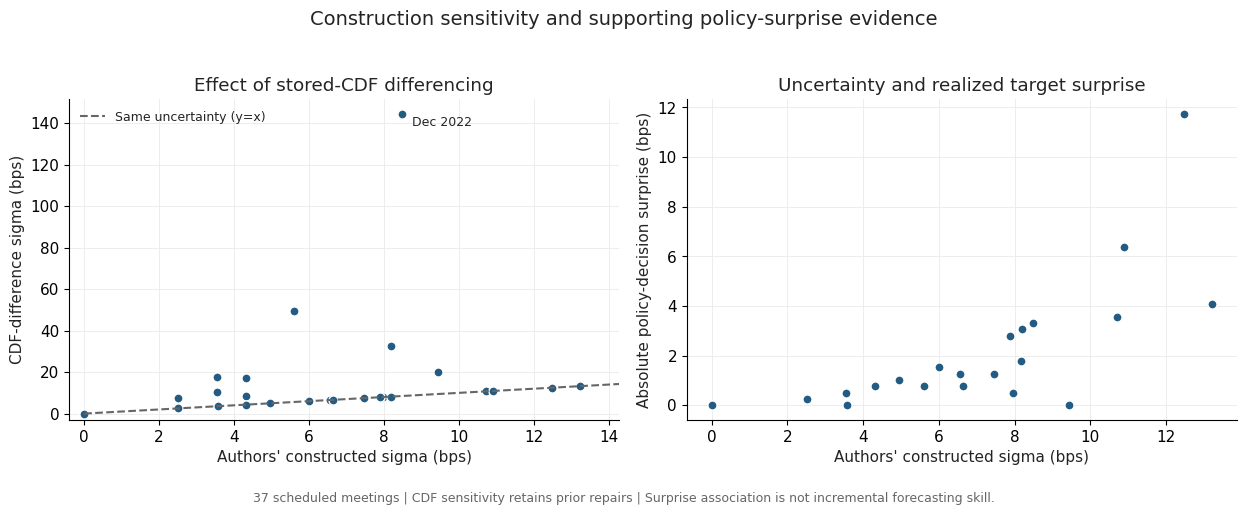

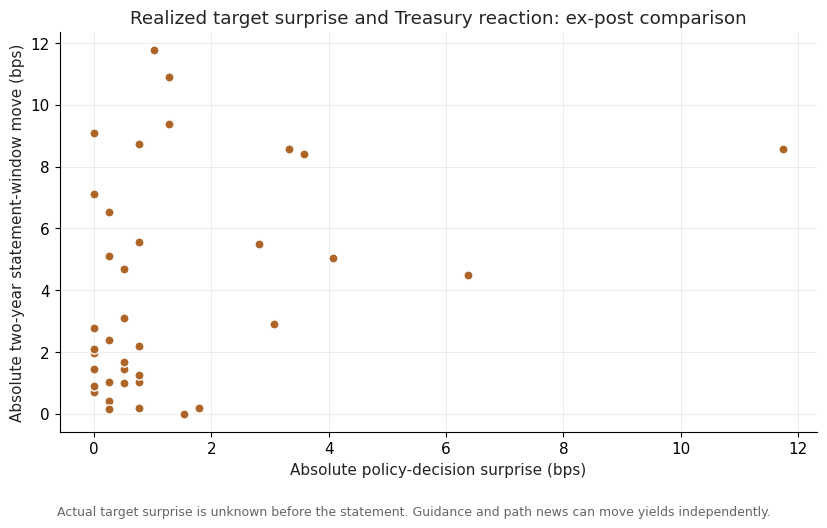

Saved six derived support tables, two figures and source provenance.
Main 37-event Treasury analysis is unchanged.
No calibration, causality or forecasting success is established by this supporting exercise.
Save to ResearchProject / main as 07_construction_and_policy_surprise.ipynb.


In [33]:
required_outputs = ["enriched", "construction_audit", "policy_audit",
                    "independent", "construction_results", "support_correlations", "support_models"]
missing_outputs = [name for name in required_outputs if name not in globals()]
if missing_outputs:
    raise RuntimeError("Run sections 1–3 before section 4. Missing: " + ", ".join(missing_outputs))
# Rebuild from input tables; do not depend on a previously mutated study table.
study = enriched.merge(construction_audit, on="meeting_date", how="left", validate="one_to_one")
study = study.merge(policy_audit, on="meeting_date", how="left", validate="one_to_one")
study = study.merge(independent[["Date", "abs_MP1_bps"]], left_on="meeting_date",
                    right_on="Date", how="left", validate="one_to_one")
assert "abs_policy_surprise_bps" in study.columns
assert study["abs_policy_surprise_bps"].notna().all()
fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.1))
valid = study.dropna(subset=["cdf_difference_sigma_bps"])
axes[0].scatter(valid["kalshi_sigma_bps"], valid["cdf_difference_sigma_bps"],
                color=BLUE, edgecolor="white", s=43)
hi = max(valid["kalshi_sigma_bps"].max(), valid["cdf_difference_sigma_bps"].max()) * 1.05
x_hi = valid["kalshi_sigma_bps"].max() * 1.08
axes[0].plot([0, x_hi], [0, x_hi], color=GREY, linestyle="--", label="Same uncertainty (y=x)")
axes[0].set_xlim(-0.4, x_hi)
axes[0].set_ylim(-3, hi)
largest = valid.loc[valid["cdf_difference_sigma_bps"].idxmax()]
axes[0].annotate(largest["meeting_date"].strftime("%b %Y"),
                 (largest["kalshi_sigma_bps"], largest["cdf_difference_sigma_bps"]),
                 xytext=(7, -8), textcoords="offset points", fontsize=9)
axes[0].set(title="Effect of stored-CDF differencing",
            xlabel="Authors' constructed sigma (bps)",
            ylabel="CDF-difference sigma (bps)")
axes[0].legend(frameon=False, fontsize=9)
axes[1].scatter(study["kalshi_sigma_bps"], study["abs_policy_surprise_bps"],
                color=BLUE, edgecolor="white", s=43)
axes[1].set(title="Uncertainty and realized target surprise",
            xlabel="Authors' constructed sigma (bps)",
            ylabel="Absolute policy-decision surprise (bps)")
for ax in axes:
    ax.grid(color="#EAEAEA", linewidth=0.6)
    ax.set_axisbelow(True)
fig.suptitle("Construction sensitivity and supporting policy-surprise evidence", fontsize=14)
fig.text(0.5, 0.015,
         "37 scheduled meetings | CDF sensitivity retains prior repairs | Surprise association is not incremental forecasting skill.",
         ha="center", fontsize=9, color=GREY)
fig.tight_layout(rect=(0, 0.055, 1, 0.95))
fig.savefig(FIGURES / "04_construction_policy_surprise.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8.4, 5.3))
ax.scatter(study["abs_policy_surprise_bps"], study["abs_ust2y_bps"],
           color=ORANGE, edgecolor="white", s=44)
ax.set(title="Realized target surprise and Treasury reaction: ex-post comparison",
       xlabel="Absolute policy-decision surprise (bps)",
       ylabel="Absolute two-year statement-window move (bps)")
ax.grid(color="#EAEAEA", linewidth=0.6)
ax.set_axisbelow(True)
fig.text(0.5, 0.015, "Actual target surprise is unknown before the statement. Guidance and path news can move yields independently.",
         ha="center", fontsize=9, color=GREY)
fig.tight_layout(rect=(0, 0.055, 1, 1))
fig.savefig(FIGURES / "05_realized_surprise_yield.png", dpi=160)
plt.show()

OUTPUT = Path("research_outputs")
OUTPUT.mkdir(exist_ok=True)
for name, table in {
    "construction_audit": construction_audit,
    "construction_sensitivities": construction_results,
    "policy_target_audit": policy_audit,
    "supporting_correlations": support_correlations,
    "supporting_models": support_models,
    "dataset_with_policy_surprise": study
}.items():
    table.to_csv(OUTPUT / f"support_{name}.csv", index=False)
manifest = {
    "source_receipts": source_receipts,
    "realization_definition": "Post-meeting day+1 target-range midpoint versus previous-day midpoint; day+2 stability checked",
    "expectation_definition": "Authors' published midpoint-based mean; changes relative to previous target midpoint",
    "construction_sensitivity": "Differencing the stored adjusted CDF with original 1/99 tail convention and support; not raw reconstruction",
    "hypothesis_status": "Exploratory supporting analysis and robustness; main specification unchanged",
    "unresolved": [
        "Full raw-data reconstruction and exact price-age sensitivity",
        "Alternative pre-announcement timing conventions",
        "External pre-announcement policy-expectation benchmark",
        "Calibration of implied distributions and real-time-vintage availability"
    ]
}
(OUTPUT / "supporting_analysis_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved six derived support tables, two figures and source provenance.")
print("Main 37-event Treasury analysis is unchanged.")
print("No calibration, causality or forecasting success is established by this supporting exercise.")
print("Save to ResearchProject / main as 07_construction_and_policy_surprise.ipynb.")
